# muP LR plots
Final eval loss (`final_ce`) vs learning rate for the muP width sweep (W&B tag `mup_width_sweep`, configs `configs/jm/feature/mup_width_{sp,simplep}*.yaml`, including the `_high_lr` and `_h16` extensions; the full-muP arm's configs were dropped, its runs stay in W&B, see `documents/notes/simplep_over_mup.md`): one panel per grid, side by side on a shared y axis, one line per width.
A star marks each width's best LR. muP works if the stars line up across widths in the muP and simpleP panels, while in the no-muP panel they move to lower LRs as width grows.
At h4 (the base width) the three grids run the same config, so their h4 lines should match.
Circles with solid lines are finished runs; pass `loss_col="summary/steps/eval/loss"` to also see running runs as squares with dashed lines (latest eval loss).
`flatten` and `get_runs` are copied from `lr_plots.ipynb`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import wandb
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

sys.path.insert(0, str(Path.cwd().parent))
from src.core.utils import solve_config_lr

In [2]:
def flatten(d, prefix):
    out = {}
    for k, v in d.items():
        if isinstance(v, dict):
            out.update(flatten(v, f"{prefix}{k}/"))
        else:
            out[f"{prefix}{k}"] = v
    return out


def get_runs(tags, negative_tags=(), project="ideascv_llms/llm-random-test"):
    """Runs with all `tags` and none of `negative_tags`; columns config/..., summary/... and lr."""
    filters = {
        "$and": [{"tags": t} for t in tags]
        + [{"tags": {"$nin": [t]}} for t in negative_tags]
    }
    rows = [
        {
            "id": run.id,
            "name": run.name,
            "state": run.state,
            "tags": run.tags,
            **flatten(run.config, "config/"),
            **flatten(run.summary._json_dict, "summary/"),
        }
        for run in wandb.Api().runs(project, filters=filters)
    ]
    if not rows:
        raise ValueError(f"no runs with tags {tags} and without {list(negative_tags)}")
    df = pd.DataFrame(rows)
    df["lr"] = df["config/trainer/learning_rate"].map(lambda x: solve_config_lr(x)[0])
    print(f"{len(df)} runs")
    return df


# Arm tag -> panel title, in panel order.
ARMS = {
    "sp": "no muP (adamw_groups)",
    "mup": "muP (dropped)",
    "simplep": "simpleP (adamw_simplep)",
}
WIDTH = "config/common/h"
# One blue, light (narrow) to dark (wide); the lightest still has 2:1 contrast on white.
RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]


def width_colors(df):
    """One color per width over all arms, so a width has the same color in every panel."""
    widths = sorted(df[WIDTH].unique())
    cmap = LinearSegmentedColormap.from_list("width", RAMP)
    return {h: cmap(i / max(len(widths) - 1, 1)) for i, h in enumerate(widths)}


def legend_handles(colors):
    """The widths, then what the markers mean; one legend for all panels."""
    widths = [
        Line2D([], [], color=c, marker="o", linewidth=2, label=f"h{h}")
        for h, c in colors.items()
    ]
    return widths + [
        Line2D(
            [],
            [],
            color="0.4",
            marker="*",
            markersize=12,
            linestyle="none",
            label="best LR",
        ),
        Line2D([], [], color="0.4", marker="s", linestyle="--", label="running"),
    ]


def finished_runs(df, loss_col):
    done = df.dropna(subset=[loss_col])
    return done[done["summary/step"] + 1 >= done["config/trainer/n_steps"]]


def plot_arm(df, ax, colors, title, loss_col):
    """Loss vs lr, one line per width; runs at the same lr are averaged, a star marks the best lr."""
    df = df.dropna(subset=[loss_col]).assign(
        finished=lambda d: d["summary/step"] + 1 >= d["config/trainer/n_steps"]
    )
    for h, group in df.groupby(WIDTH):
        for finished, marker, linestyle in [(True, "o", "-"), (False, "s", "--")]:
            part = group[group["finished"] == finished]
            if part.empty:
                continue
            means = part.groupby("lr")[loss_col].mean()
            ax.plot(
                means.index,
                means.values,
                marker=marker,
                markersize=6,
                linewidth=2,
                linestyle=linestyle,
                color=colors[h],
            )
            if finished:
                ax.plot(
                    means.idxmin(),
                    means.min(),
                    marker="*",
                    markersize=16,
                    markeredgecolor="white",
                    color=colors[h],
                    linestyle="none",
                )
                # at the lowest lr, where the widths are ordered and apart
                ax.annotate(
                    f"h{h}",
                    (means.index[0], means.values[0]),
                    xytext=(-6, 0),
                    textcoords="offset points",
                    ha="right",
                    va="center",
                    fontsize=9,
                    color="0.3",
                )
    ax.set_xscale("log", base=2)
    ax.margins(x=0.1)
    ax.set_xlabel("learning rate")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)


def best_lr_table(df, loss_col):
    """Best lr (2^-x) and its loss per width and arm, finished runs only."""
    rows = []
    for (arm, h), group in finished_runs(df, loss_col).groupby(["arm", WIDTH]):
        means = group.groupby("config/trainer/learning_rate")[loss_col].mean()
        rows.append(
            {
                "h": h,
                "arm": ARMS[arm],
                "best lr": f"2^-{means.idxmin():g} ({means.min():.3f})",
            }
        )
    table = pd.DataFrame(rows).pivot(index="h", columns="arm", values="best lr")
    return table.reindex(columns=[t for t in ARMS.values() if t in table.columns])

In [3]:
tags = ["mup_width_sweep"]
negative_tags = ["remove"]

df = get_runs(tags, negative_tags)
df["arm"] = df["tags"].map(lambda t: next((a for a in ARMS if a in t), None))
df.groupby(["arm", WIDTH]).size().unstack()  # runs per grid and width

wandb: Currently logged in as: j321m (ideascv_llms) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


122 runs


config/common/h,2,4,8,12,16
arm,,,,,
mup,9,9,9,9,5
simplep,9,9,9,9,5
sp,9,9,9,9,4


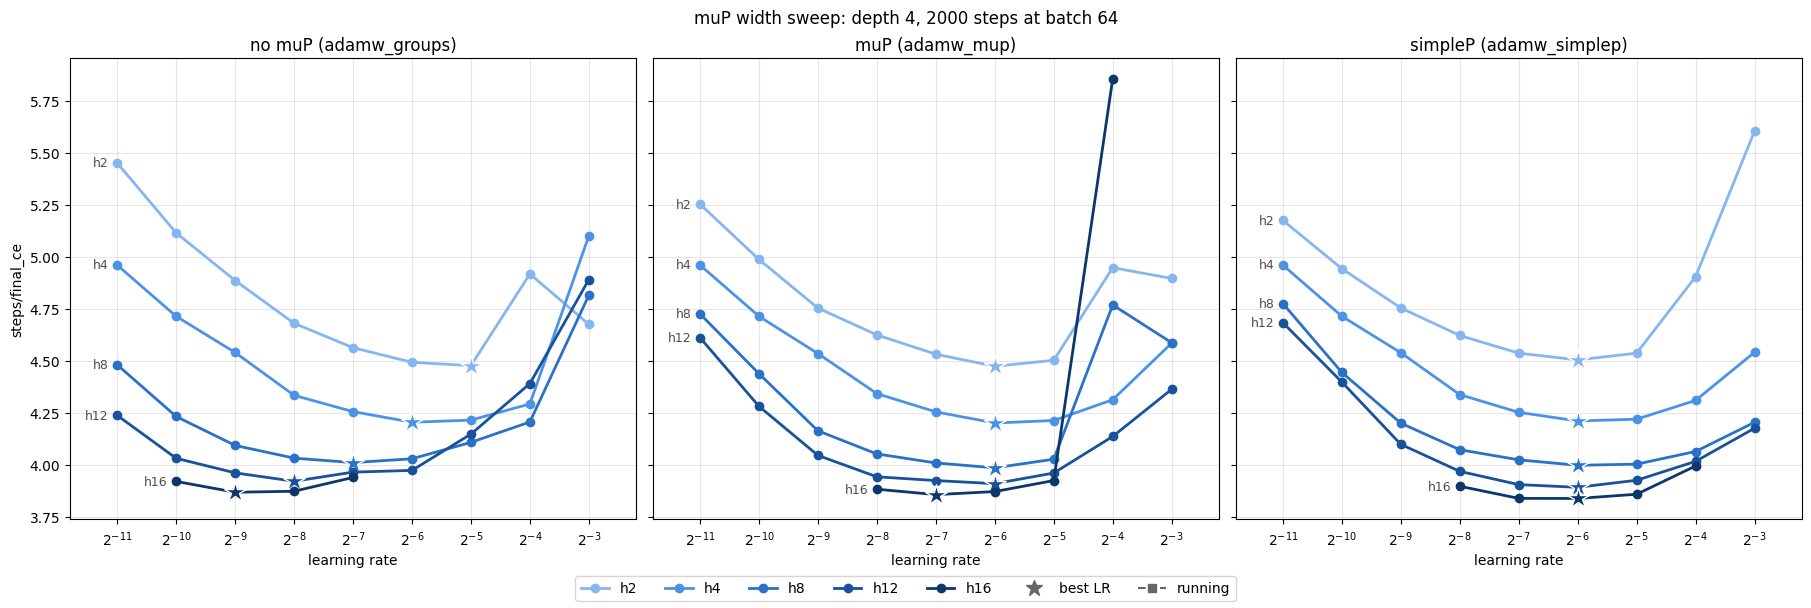

In [4]:
loss_col = "summary/steps/final_ce"
ylim = None  # e.g. (3.2, 4.5) if diverged high-LR runs stretch the axis

colors = width_colors(df)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, layout="constrained")
for ax, (arm, title) in zip(axes, ARMS.items()):
    plot_arm(df[df["arm"] == arm], ax, colors, title, loss_col)
axes[0].set_ylabel(loss_col.removeprefix("summary/"))
if ylim is not None:
    axes[0].set_ylim(ylim)
fig.legend(
    handles=legend_handles(colors), loc="outside lower center", ncols=len(colors) + 2
)
fig.suptitle("muP width sweep: depth 4, 2000 steps at batch 64")
plt.show()

In [5]:
best_lr_table(df, loss_col)

arm,no muP (adamw_groups),muP (adamw_mup),simpleP (adamw_simplep)
h,,,
2,2^-5 (4.477),2^-6 (4.474),2^-6 (4.504)
4,2^-6 (4.205),2^-6 (4.201),2^-6 (4.211)
8,2^-7 (4.011),2^-6 (3.985),2^-6 (3.998)
12,2^-8 (3.921),2^-6 (3.909),2^-6 (3.892)
16,2^-9 (3.868),2^-7 (3.857),2^-6 (3.838)
